# Machine Learning and Rolling-Origin Backtesting



This notebook develops and evaluates a Random Forest regression model to predict monthly house prices across London boroughs.

The model predicts the average house price for each borough and month using information from earlier periods, including previous house prices, housing transactions, economic variables and time-related features.

Model performance is tested using an expanding-window yearly backtesting approach. For each test year, the model is trained on all available data from previous years and then used to predict house prices for the following year. This helps to evaluate the model in a way that is closer to real forecasting.

The Random Forest model is compared with a seasonal naive baseline. This baseline predicts the current month's house price using the price from the same month in the previous year.

Mean Absolute Error (MAE) is used as the main evaluation metric because it gives a clear measure of the average prediction error in pounds. Root Mean Squared Error (RMSE) and R-squared (R²) are also reported to provide additional information about model performance.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42

In [2]:
PROJECT_DIR = Path(".")

DATA_DIR = PROJECT_DIR
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("Results directory:", RESULTS_DIR.resolve())
print("Figures directory:", FIGURES_DIR.resolve())

Results directory: /content/results
Figures directory: /content/figures


In [3]:
file_path = DATA_DIR / "london_housing_model_extended.csv"

if not file_path.exists():
    raise FileNotFoundError(
        f"{file_path} was not found. "
        "Run Notebook 03 and export london_housing_model_extended.csv first."
    )

df = pd.read_csv(file_path)

df["date"] = pd.to_datetime(df["date"])

df = (
    df.sort_values(["date", "area"])
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of areas:", df["area"].nunique())

display(df.head())

Dataset shape: (6946, 32)
Date range: 2002-02-01 00:00:00 to 2019-11-01 00:00:00
Number of areas: 33


,date,area,average_price,year,quarter,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_12,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m_lag_1,post_2008
0,2002-02-01,barking and dagenham,100229,2002,1,14,0.866,0.500,"98,713.000","95,918.000","90,462.000","83,266.000","97,114.333","94,666.500","90,028.167","5,460.863",2.069,5.481,19.880,216.000,282.000,238.000,248.333,267.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
1,2002-02-01,barnet,202713,2002,1,14,0.866,0.500,"203,249.000","198,610.000","187,691.000","178,108.000","200,883.667","195,936.000","187,877.833","9,465.678",1.224,4.595,15.828,501.000,581.000,388.000,516.333,571.167,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
2,2002-02-01,bexley,124611,2002,1,14,0.866,0.500,"124,283.000","123,381.000","119,312.000","111,439.000","123,366.000","122,091.667","117,617.833","5,006.182",1.510,1.954,11.771,319.000,540.000,331.000,441.667,435.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
3,2002-02-01,brent,171147,2002,1,14,0.866,0.500,"168,671.000","163,992.000","160,832.000","150,110.000","166,165.333","164,464.000","158,984.417","6,345.480",1.711,2.650,13.732,315.000,430.000,297.000,362.000,394.500,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0
4,2002-02-01,bromley,172833,2002,1,14,0.866,0.500,"173,150.000","170,870.000","164,849.000","154,097.000","172,201.000","169,790.167","163,759.750","6,960.504",0.329,1.731,12.717,445.000,681.000,410.000,564.333,630.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,0


In [4]:
print(df.columns.tolist())

['date', 'area', 'average_price', 'year', 'quarter', 'time_index', 'month_sin', 'month_cos', 'price_lag_1', 'price_lag_3', 'price_lag_6', 'price_lag_12', 'price_rolling_mean_3', 'price_rolling_mean_6', 'price_rolling_mean_12', 'price_rolling_std_12', 'price_mom_growth_lag_1', 'price_3m_growth_lag_1', 'price_yoy_growth_lag_1', 'houses_sold_lag_1', 'houses_sold_lag_3', 'houses_sold_lag_12', 'houses_sold_rolling_mean_3', 'houses_sold_rolling_mean_12', 'cpi_lag_1', 'cpi_lag_3', 'cpi_lag_12', 'bank_rate_lag_1', 'bank_rate_lag_3', 'bank_rate_lag_12', 'bank_rate_change_1m_lag_1', 'post_2008']


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6946 entries, 0 to 6945
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   date                         6946 non-null   datetime64[ns]
 1   area                         6946 non-null   object        
 2   average_price                6946 non-null   int64         
 3   year                         6946 non-null   int64         
 4   quarter                      6946 non-null   int64         
 5   time_index                   6946 non-null   int64         
 6   month_sin                    6946 non-null   float64       
 7   month_cos                    6946 non-null   float64       
 8   price_lag_1                  6946 non-null   float64       
 9   price_lag_3                  6946 non-null   float64       
 10  price_lag_6                  6946 non-null   float64       
 11  price_lag_12                 6946 non-null 

In [6]:
quality_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_pct": df.isna().mean() * 100,
    "unique_values": df.nunique()
}).sort_values("missing_values", ascending=False)

display(quality_summary.head(20))

,missing_values,missing_pct,unique_values
date,0,0.000,214
area,0,0.000,33
average_price,0,0.000,6889
year,0,0.000,18
quarter,0,0.000,4
time_index,0,0.000,214
month_sin,0,0.000,11
month_cos,0,0.000,11
price_lag_1,0,0.000,6889
price_lag_3,0,0.000,6890


In [7]:
print(
    "Duplicate area-date rows:",
    df.duplicated(["area", "date"]).sum()
)

print(
    "Dates sorted:",
    df["date"].is_monotonic_increasing
)

print(
    "Infinite values:",
    np.isinf(
        df.select_dtypes(include=np.number)
    ).sum().sum()
)

Duplicate area-date rows: 0
Dates sorted: True
Infinite values: 0


In [8]:
if df.duplicated(["area", "date"]).any():
    raise ValueError("Duplicate area-date observations were detected.")

In [9]:
year_month_counts = (
    df.groupby("year")["date"]
      .apply(lambda x: x.dt.to_period("M").nunique())
      .sort_index()
)

display(year_month_counts.to_frame("number_of_months"))

,number_of_months
year,
2002,11
2003,12
2004,12
2005,12
2006,12
2007,12
2008,12
2009,12
2010,12


In [10]:
complete_years = year_month_counts[
    year_month_counts == 12
].index.tolist()

print("Complete years:")
print(complete_years)

Complete years:
[2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]


### Prediction target

The prediction target is average_price, representing the average nominal house price for a London borough in a particular month.

The model is evaluated one year at a time. For each test year, all earlier years are used for training.



In [11]:
numeric_features = [
    # Time and seasonality
    "time_index",
    "month_sin",
    "month_cos",

    # Historical house prices
    "price_lag_1",
    "price_lag_3",
    "price_lag_6",
    "price_lag_12",

    # Historical price summaries
    "price_rolling_mean_3",
    "price_rolling_mean_6",
    "price_rolling_mean_12",
    "price_rolling_std_12",

    # Historical price growth
    "price_mom_growth_lag_1",
    "price_3m_growth_lag_1",
    "price_yoy_growth_lag_1",

    # Transaction activity
    "houses_sold_lag_1",
    "houses_sold_lag_3",
    "houses_sold_lag_12",
    "houses_sold_rolling_mean_3",
    "houses_sold_rolling_mean_12",

    # Macroeconomic variables
    "cpi_lag_1",
    "cpi_lag_3",
    "cpi_lag_12",
    "bank_rate_lag_1",
    "bank_rate_lag_3",
    "bank_rate_lag_12",
    "bank_rate_change_1m_lag_1"
]

categorical_features = [
    "area"
]

all_features = numeric_features + categorical_features

In [12]:
target = "average_price"

if "all_features" not in globals():
    raise NameError(
        "all_features is not defined. Run the feature-definition cell first."
    )

required_columns = list(dict.fromkeys(
    ["date", "year", target, "price_lag_12"] + all_features
))

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise KeyError(
        f"The following required columns are missing: {missing_columns}"
    )

print("All required columns are available.")
print("Target:", target)
print("Number of features:", len(all_features))

All required columns are available.
Target: average_price
Number of features: 27


In [13]:
model_columns = [
    "date",
    "year",
    target,
    "price_lag_12"
] + all_features

model_df = (
    df[model_columns]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .sort_values(["date", "area"])
    .reset_index(drop=True)
)

print("Rows before final filtering:", len(df))
print("Rows available for modelling:", len(model_df))
print("Earliest modelling date:", model_df["date"].min())
print("Latest modelling date:", model_df["date"].max())
print("Areas:", model_df["area"].nunique())

display(model_df.head())

Rows before final filtering: 6946
Rows available for modelling: 6946
Earliest modelling date: 2002-02-01 00:00:00
Latest modelling date: 2019-11-01 00:00:00
Areas: 33


,date,year,average_price,price_lag_12,time_index,month_sin,month_cos,price_lag_1,price_lag_3,price_lag_6,price_lag_12,price_rolling_mean_3,price_rolling_mean_6,price_rolling_mean_12,price_rolling_std_12,price_mom_growth_lag_1,price_3m_growth_lag_1,price_yoy_growth_lag_1,houses_sold_lag_1,houses_sold_lag_3,houses_sold_lag_12,houses_sold_rolling_mean_3,houses_sold_rolling_mean_12,cpi_lag_1,cpi_lag_3,cpi_lag_12,bank_rate_lag_1,bank_rate_lag_3,bank_rate_lag_12,bank_rate_change_1m_lag_1,area
0,2002-02-01,2002,100229,"83,266.000",14,0.866,0.500,"98,713.000","95,918.000","90,462.000","83,266.000","97,114.333","94,666.500","90,028.167","5,460.863",2.069,5.481,19.880,216.000,282.000,238.000,248.333,267.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,barking and dagenham
1,2002-02-01,2002,202713,"178,108.000",14,0.866,0.500,"203,249.000","198,610.000","187,691.000","178,108.000","200,883.667","195,936.000","187,877.833","9,465.678",1.224,4.595,15.828,501.000,581.000,388.000,516.333,571.167,67.032,67.150,66.522,4.000,4.117,5.812,0.000,barnet
2,2002-02-01,2002,124611,"111,439.000",14,0.866,0.500,"124,283.000","123,381.000","119,312.000","111,439.000","123,366.000","122,091.667","117,617.833","5,006.182",1.510,1.954,11.771,319.000,540.000,331.000,441.667,435.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,bexley
3,2002-02-01,2002,171147,"150,110.000",14,0.866,0.500,"168,671.000","163,992.000","160,832.000","150,110.000","166,165.333","164,464.000","158,984.417","6,345.480",1.711,2.650,13.732,315.000,430.000,297.000,362.000,394.500,67.032,67.150,66.522,4.000,4.117,5.812,0.000,brent
4,2002-02-01,2002,172833,"154,097.000",14,0.866,0.500,"173,150.000","170,870.000","164,849.000","154,097.000","172,201.000","169,790.167","163,759.750","6,960.504",0.329,1.731,12.717,445.000,681.000,410.000,564.333,630.000,67.032,67.150,66.522,4.000,4.117,5.812,0.000,bromley


In [14]:
#league control
forbidden_predictors = [
    "average_price",
    "real_price_2015",
    "price_mom_growth_pct",
    "price_3m_growth_pct",
    "price_yoy_growth_pct",
    "houses_sold",
    "cpi_index_2015_100",
    "bank_rate_monthly_avg"
]

leakage_found = [
    column
    for column in all_features
    if column in forbidden_predictors
]

print("Potential leakage variables:", leakage_found)

Potential leakage variables: []


### Forecast interpretation

The evaluation is organised by year, but the predictors include lagged monthly observations. Therefore, the exercise represents a rolling one-step-ahead monthly forecasting design evaluated across each test year.

For example, the prediction for February may use information observed in January. It should not be interpreted as predicting all twelve months of the test year simultaneously from the final date of the preceding year.

The seasonal naive baseline uses the corresponding month's observed price from the previous year.

In [ ]:
def calculate_regression_metrics(y_true, y_pred):
    
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r_squared = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R_squared": r_squared
    }

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [17]:
random_forest = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

used a pipeline to combine preprocessing and Random Forest into one consistent process, making training and prediction cleaner and helping prevent data leakage

In [ ]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest)
    ]
)

rf_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', 'passthrough',
                                                  ['time_index', 'month_sin',
                                                   'month_cos', 'price_lag_1',
                                                   'price_lag_3', 'price_lag_6',
                                                   'price_lag_12',
                                                   'price_rolling_mean_3',
                                                   'price_rolling_mean_6',
                                                   'price_rolling_mean_12',
                                                   'price_rolling_std_12',
                                                   'price_mom_growth_lag_1',
                                                   'price_3m_growth_lag_1',
                                                   'price_yoy_growth_lag_1'...
                                                   'bank_rate_lag_1',
                                                   'bank_rate_lag_3',
                                                   'bank_rate_lag_12',
                                                   'bank_rate_change_1m_lag_1']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['area'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 RandomForestRegressor(max_depth=15, max_features='sqrt',
                                       min_samples_leaf=3, min_samples_split=5,
                                       n_estimators=300, n_jobs=-1,
                                       random_state=42))])

## Random Forest justification

Random Forest was chosen as the main machine-learning model because it can capture more complex and non-linear relationships between house prices and the other variables. These include previous house prices, transaction activity, economic factors, seasonal patterns and differences between London boroughs.

Unlike a standard linear regression model, Random Forest does not assume that each variable has a simple linear relationship with house prices. It can also handle interactions between different variables and is generally less affected by extreme values. Another useful feature is that it can show which variables are more important for making predictions.

However, Random Forest also has some limitations. Its predictions are more difficult to explain compared with the coefficients from a linear regression model. In addition, tree-based models can have difficulty predicting house prices outside the range of values seen in the training data. These limitations are considered when interpreting and evaluating the model results.

In [19]:
minimum_training_years = 5

first_available_year = int(model_df["year"].min())
last_available_year = int(model_df["year"].max())

candidate_test_years = [
    year
    for year in complete_years
    if year >= first_available_year + minimum_training_years
    and year <= last_available_year
]

print("Candidate test years:", candidate_test_years)

Candidate test years: [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018]


In [20]:
final_holdout_year = max(candidate_test_years)

backtest_years = [
    year
    for year in candidate_test_years
    if year < final_holdout_year
]

print("Backtest years:", backtest_years)
print("Final untouched hold-out year:", final_holdout_year)

Backtest years: [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017]
Final untouched hold-out year: 2018


In [21]:
year_summary = (
    model_df.groupby("year")
    .agg(
        rows=("average_price", "size"),
        areas=("area", "nunique"),
        months=("date", lambda x: x.dt.to_period("M").nunique())
    )
)

display(year_summary.loc[candidate_test_years])

,rows,areas,months
year,,,
2007,396,33,12
2008,396,33,12
2009,396,33,12
2010,387,33,12
2011,384,32,12
2012,384,32,12
2013,384,32,12
2014,384,32,12
2015,384,32,12


Yearly backtest function

In [ ]:
def run_yearly_backtest(
    data,
    test_years,
    feature_columns,
    target_column,
    model_pipeline
):
    """
    Run expanding-window yearly backtesting.

    For each test year:
    - use all earlier observations for training;
    - predict observations in the test year;
    - evaluate a seasonal naive baseline;
    - evaluate Random Forest;
    - store row-level predictions.

    Returns
    -------
    yearly_results : pandas.DataFrame
        One row per model and test year.
    predictions : pandas.DataFrame
        Row-level actual and predicted values.
    fitted_models : dict
        Fitted pipeline for each test year.
    """

    yearly_records = []
    prediction_records = []
    fitted_models = {}

    for test_year in test_years:

        train_df = data[
            data["year"] < test_year
        ].copy()

        test_df = data[
            data["year"] == test_year
        ].copy()

        if train_df.empty or test_df.empty:
            print(f"Skipping {test_year}: insufficient data.")
            continue

        X_train = train_df[feature_columns]
        y_train = train_df[target_column]

        X_test = test_df[feature_columns]
        y_test = test_df[target_column]

        # Seasonal naive baseline
        baseline_predictions = test_df["price_lag_12"]

        baseline_metrics = calculate_regression_metrics(
            y_test,
            baseline_predictions
        )

        yearly_records.append({
            "test_year": test_year,
            "model": "Seasonal naive baseline",
            "training_rows": len(train_df),
            "testing_rows": len(test_df),
            "training_start": train_df["date"].min(),
            "training_end": train_df["date"].max(),
            **baseline_metrics
        })

        model_pipeline.fit(X_train, y_train)

        rf_predictions = model_pipeline.predict(X_test)

        rf_metrics = calculate_regression_metrics(
            y_test,
            rf_predictions
        )

        yearly_records.append({
            "test_year": test_year,
            "model": "Random Forest",
            "training_rows": len(train_df),
            "testing_rows": len(test_df),
            "training_start": train_df["date"].min(),
            "training_end": train_df["date"].max(),
            **rf_metrics
        })

        year_predictions = test_df[
            [
                "date",
                "year",
                "area",
                target_column,
                "price_lag_12"
            ]
        ].copy()

        year_predictions = year_predictions.rename(
            columns={
                target_column: "actual_price",
                "price_lag_12": "baseline_prediction"
            }
        )

        year_predictions["rf_prediction"] = rf_predictions

        year_predictions["baseline_error"] = (
            year_predictions["actual_price"]
            - year_predictions["baseline_prediction"]
        )

        year_predictions["rf_error"] = (
            year_predictions["actual_price"]
            - year_predictions["rf_prediction"]
        )

        year_predictions["baseline_absolute_error"] = (
            year_predictions["baseline_error"].abs()
        )

        year_predictions["rf_absolute_error"] = (
            year_predictions["rf_error"].abs()
        )

        prediction_records.append(year_predictions)

        fitted_models[test_year] = model_pipeline

        print(
            f"Completed {test_year} | "
            f"Baseline MAE: £{baseline_metrics['MAE']:,.0f} | "
            f"RF MAE: £{rf_metrics['MAE']:,.0f}"
        )

    yearly_results = pd.DataFrame(yearly_records)

    predictions = pd.concat(
        prediction_records,
        ignore_index=True
    )

    return yearly_results, predictions, fitted_models

expanding-window yearly backtesting

In [ ]:
from sklearn.base import clone

def run_yearly_backtest(
    data,
    test_years,
    feature_columns,
    target_column,
    model_pipeline
):
    yearly_records = []
    prediction_records = []
    fitted_models = {}

    duplicate_columns = data.columns[
        data.columns.duplicated()
    ].tolist()

    if duplicate_columns:
        raise ValueError(
            f"Duplicate columns detected in modelling data: "
            f"{duplicate_columns}"
        )

    for test_year in test_years:

        print(f"\nProcessing test year: {test_year}")
        train_df = data[
            data["year"] < test_year
        ].copy()

        test_df = data[
            data["year"] == test_year
        ].copy()

        if train_df.empty:
            print(
                f"Skipping {test_year}: no training data."
            )
            continue

        if test_df.empty:
            print(
                f"Skipping {test_year}: no testing data."
            )
            continue

        X_train = train_df.loc[:, feature_columns]
        y_train = train_df[target_column].astype(float)

        X_test = test_df.loc[:, feature_columns]
        y_test = test_df[target_column].astype(float)

        y_test_array = (
            y_test
            .to_numpy()
            .reshape(-1)
        )

        if X_train.isna().any().any():
            raise ValueError(
                f"Missing training features for {test_year}."
            )

        if X_test.isna().any().any():
            raise ValueError(
                f"Missing test features for {test_year}."
            )

        if y_train.isna().any():
            raise ValueError(
                f"Missing training targets for {test_year}."
            )

        if y_test.isna().any():
            raise ValueError(
                f"Missing test targets for {test_year}."
            )

        # Seasonal naive baseline
        baseline_predictions = (
            test_df["price_lag_12"]
            .astype(float)
            .to_numpy()
            .reshape(-1)
        )

        if len(y_test_array) != len(baseline_predictions):
            raise ValueError(
                f"Baseline length mismatch in {test_year}: "
                f"{len(y_test_array)} actual values versus "
                f"{len(baseline_predictions)} predictions."
            )

        baseline_metrics = calculate_regression_metrics(
            y_test_array,
            baseline_predictions
        )

        yearly_records.append({
            "test_year": test_year,
            "model": "Seasonal naïve baseline",
            "training_rows": len(train_df),
            "testing_rows": len(test_df),
            "training_start": train_df["date"].min(),
            "training_end": train_df["date"].max(),
            "testing_start": test_df["date"].min(),
            "testing_end": test_df["date"].max(),
            **baseline_metrics
        })
        # Random Forest
        year_model = clone(model_pipeline)

        year_model.fit(
            X_train,
            y_train
        )

        rf_predictions = (
            np.asarray(
                year_model.predict(X_test)
            )
            .reshape(-1)
        )

        if len(y_test_array) != len(rf_predictions):
            raise ValueError(
                f"Random Forest length mismatch in {test_year}: "
                f"{len(y_test_array)} actual values versus "
                f"{len(rf_predictions)} predictions."
            )

        rf_metrics = calculate_regression_metrics(
            y_test_array,
            rf_predictions
        )

        yearly_records.append({
            "test_year": test_year,
            "model": "Random Forest",
            "training_rows": len(train_df),
            "testing_rows": len(test_df),
            "training_start": train_df["date"].min(),
            "training_end": train_df["date"].max(),
            "testing_start": test_df["date"].min(),
            "testing_end": test_df["date"].max(),
            **rf_metrics
        })

        # Save predictions
        year_predictions = test_df.loc[
            :,
            [
                "date",
                "year",
                "area",
                target_column,
                "price_lag_12"
            ]
        ].copy()

        year_predictions = year_predictions.rename(
            columns={
                target_column: "actual_price",
                "price_lag_12": "baseline_prediction"
            }
        )

        year_predictions["rf_prediction"] = (
            rf_predictions
        )

        year_predictions["baseline_error"] = (
            year_predictions["actual_price"]
            - year_predictions["baseline_prediction"]
        )

        year_predictions["rf_error"] = (
            year_predictions["actual_price"]
            - year_predictions["rf_prediction"]
        )

        year_predictions["baseline_absolute_error"] = (
            year_predictions["baseline_error"].abs()
        )

        year_predictions["rf_absolute_error"] = (
            year_predictions["rf_error"].abs()
        )

        prediction_records.append(
            year_predictions
        )

        fitted_models[test_year] = year_model

        improvement_pct = (
            (
                baseline_metrics["MAE"]
                - rf_metrics["MAE"]
            )
            / baseline_metrics["MAE"]
        ) * 100

        print(
            f"Training period: "
            f"{train_df['date'].min().date()} to "
            f"{train_df['date'].max().date()}"
        )

        print(
            f"Testing period: "
            f"{test_df['date'].min().date()} to "
            f"{test_df['date'].max().date()}"
        )

        print(
            f"Baseline MAE: "
            f"£{baseline_metrics['MAE']:,.0f}"
        )

        print(
            f"Random Forest MAE: "
            f"£{rf_metrics['MAE']:,.0f}"
        )

        print(
            f"Random Forest improvement: "
            f"{improvement_pct:.2f}%"
        )

    yearly_results = pd.DataFrame(
        yearly_records
    )

    if prediction_records:
        predictions = pd.concat(
            prediction_records,
            ignore_index=True
        )
    else:
        predictions = pd.DataFrame()

    return yearly_results, predictions, fitted_models

In [24]:
target = "average_price"

all_features = list(dict.fromkeys(all_features))

model_columns = list(dict.fromkeys(
    [
        "date",
        "year",
        target,
        "price_lag_12"
    ] + all_features
))

model_df = (
    df.loc[:, model_columns]
      .replace([np.inf, -np.inf], np.nan)
      .dropna()
      .sort_values(["date", "area"])
      .reset_index(drop=True)
)

model_df = model_df.loc[:, ~model_df.columns.duplicated()].copy()

duplicate_columns = model_df.columns[
    model_df.columns.duplicated()
].tolist()

if duplicate_columns:
    raise ValueError(
        f"Duplicate columns still remain: {duplicate_columns}"
    )

if model_df["price_lag_12"].ndim != 1:
    raise ValueError(
        "price_lag_12 is still duplicated."
    )

print("model_df successfully rebuilt.")
print("Shape:", model_df.shape)
print("Duplicate columns:", duplicate_columns)
print(
    "Number of price_lag_12 columns:",
    list(model_df.columns).count("price_lag_12")
)
print(
    "Date range:",
    model_df["date"].min(),
    "to",
    model_df["date"].max()
)


model_df successfully rebuilt.
Shape: (6946, 30)
Duplicate columns: []
Number of price_lag_12 columns: 1
Date range: 2002-02-01 00:00:00 to 2019-11-01 00:00:00


In [25]:
yearly_results, all_predictions, fitted_models = (
    run_yearly_backtest(
        data=model_df,
        test_years=backtest_years,
        feature_columns=all_features,
        target_column=target,
        model_pipeline=rf_pipeline
    )
)


Processing test year: 2007
Training period: 2002-02-01 to 2006-12-01
Testing period: 2007-01-01 to 2007-12-01
Baseline MAE: £42,937
Random Forest MAE: £11,605
Random Forest improvement: 72.97%

Processing test year: 2008
Training period: 2002-02-01 to 2007-12-01
Testing period: 2008-01-01 to 2008-12-01
Baseline MAE: £24,785
Random Forest MAE: £18,331
Random Forest improvement: 26.04%

Processing test year: 2009
Training period: 2002-02-01 to 2008-12-01
Testing period: 2009-01-01 to 2009-12-01
Baseline MAE: £34,972
Random Forest MAE: £9,929
Random Forest improvement: 71.61%

Processing test year: 2010
Training period: 2002-02-01 to 2009-12-01
Testing period: 2010-01-01 to 2010-12-01
Baseline MAE: £32,882
Random Forest MAE: £8,296
Random Forest improvement: 74.77%

Processing test year: 2011
Training period: 2002-02-01 to 2010-12-01
Testing period: 2011-01-01 to 2011-12-01
Baseline MAE: £11,800
Random Forest MAE: £6,887
Random Forest improvement: 41.64%

Processing test year: 2012
Train

In [26]:
display(yearly_results.head(10))

,test_year,model,training_rows,testing_rows,training_start,training_end,testing_start,testing_end,MAE,RMSE,R_squared
0,2007,Seasonal naïve baseline,1947,396,2002-02-01,2006-12-01,2007-01-01,2007-12-01,"42,936.980","51,995.545",0.784
1,2007,Random Forest,1947,396,2002-02-01,2006-12-01,2007-01-01,2007-12-01,"11,605.025","30,869.620",0.924
2,2008,Seasonal naïve baseline,2343,396,2002-02-01,2007-12-01,2008-01-01,2008-12-01,"24,785.278","31,571.873",0.929
3,2008,Random Forest,2343,396,2002-02-01,2007-12-01,2008-01-01,2008-12-01,"18,331.212","25,180.457",0.955
4,2009,Seasonal naïve baseline,2739,396,2002-02-01,2008-12-01,2009-01-01,2009-12-01,"34,971.760","42,866.659",0.852
5,2009,Random Forest,2739,396,2002-02-01,2008-12-01,2009-01-01,2009-12-01,"9,928.838","15,442.765",0.981
6,2010,Seasonal naïve baseline,3135,387,2002-02-01,2009-12-01,2010-01-01,2010-12-01,"32,882.473","43,185.978",0.897
7,2010,Random Forest,3135,387,2002-02-01,2009-12-01,2010-01-01,2010-12-01,"8,296.141","18,849.494",0.980
8,2011,Seasonal naïve baseline,3522,384,2002-02-01,2010-12-01,2011-01-01,2011-12-01,"11,800.128","20,083.590",0.981
9,2011,Random Forest,3522,384,2002-02-01,2010-12-01,2011-01-01,2011-12-01,"6,886.973","16,348.247",0.988


In [27]:
print("Backtest result rows:", len(yearly_results))
print("Prediction rows:", len(all_predictions))
print("Years evaluated:", sorted(all_predictions["year"].unique()))

Backtest result rows: 22
Prediction rows: 4263
Years evaluated: [np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)]


In [28]:
backtest_period_check = yearly_results[
    [
        "test_year",
        "model",
        "training_start",
        "training_end"
    ]
].copy()

backtest_period_check["valid_time_order"] = (
    backtest_period_check["training_end"].dt.year
    < backtest_period_check["test_year"]
)

display(backtest_period_check)

,test_year,model,training_start,training_end,valid_time_order
0,2007,Seasonal naïve baseline,2002-02-01,2006-12-01,True
1,2007,Random Forest,2002-02-01,2006-12-01,True
2,2008,Seasonal naïve baseline,2002-02-01,2007-12-01,True
3,2008,Random Forest,2002-02-01,2007-12-01,True
4,2009,Seasonal naïve baseline,2002-02-01,2008-12-01,True
5,2009,Random Forest,2002-02-01,2008-12-01,True
6,2010,Seasonal naïve baseline,2002-02-01,2009-12-01,True
7,2010,Random Forest,2002-02-01,2009-12-01,True
8,2011,Seasonal naïve baseline,2002-02-01,2010-12-01,True
9,2011,Random Forest,2002-02-01,2010-12-01,True


In [29]:
assert backtest_period_check["valid_time_order"].all(), (
    "Training and testing periods overlap."
)

print("All backtest windows use valid chronological ordering.")

All backtest windows use valid chronological ordering.


In [30]:
yearly_comparison = (
    yearly_results.pivot(
        index="test_year",
        columns="model",
        values=["MAE", "RMSE", "R_squared"]
    )
)

display(yearly_comparison)

MAE                                  RMSE  \
model     Random Forest Seasonal naïve baseline Random Forest   
test_year                                                       
2007         11,605.025              42,936.980    30,869.620   
2008         18,331.212              24,785.278    25,180.457   
2009          9,928.838              34,971.760    15,442.765   
2010          8,296.141              32,882.473    18,849.494   
2011          6,886.973              11,800.128    16,348.247   
2012          7,922.915              17,667.885    22,235.655   
2013          9,364.383              30,563.922    26,707.656   
2014         13,919.329              62,252.013    36,761.021   
2015          9,820.362              39,566.263    18,371.699   
2016         10,855.789              42,608.568    17,186.774   
2017         11,572.460              18,872.078    20,436.813   

                                      R_squared                          
model     Seasonal naïve baseline Random Forest Seasonal naïve baseline  
test_year                                                                
2007                   51,995.545         0.924                   0.784  
2008                   31,571.873         0.955                   0.929  
2009                   42,866.659         0.981                   0.852  
2010                   43,185.978         0.980                   0.897  
2011                   20,083.590         0.988                   0.981  
2012                   29,322.342         0.982                   0.969  
2013                   41,518.013         0.981                   0.953  
2014                   70,220.438         0.972                   0.899  
2015                   42,505.207         0.993                   0.962  
2016                   46,510.129         0.993                   0.948  
2017                   27,022.756         0.991                   0.984

In [36]:
print(yearly_results["model"].unique())
mae_by_year = (
    yearly_results.pivot(
        index="test_year",
        columns="model",
        values="MAE"
    )
    .reset_index()
)

mae_by_year["RF_improvement_over_baseline_pct"] = (
    (
        mae_by_year["Seasonal naïve baseline"]
        - mae_by_year["Random Forest"]
    )
    / mae_by_year["Seasonal naïve baseline"]
) * 100

display(mae_by_year)

['Seasonal naïve baseline' 'Random Forest']


model,test_year,Random Forest,Seasonal naïve baseline,RF_improvement_over_baseline_pct
0,2007,"11,605.025","42,936.980",72.972
1,2008,"18,331.212","24,785.278",26.040
2,2009,"9,928.838","34,971.760",71.609
3,2010,"8,296.141","32,882.473",74.770
4,2011,"6,886.973","11,800.128",41.636
5,2012,"7,922.915","17,667.885",55.156
6,2013,"9,364.383","30,563.922",69.361
7,2014,"13,919.329","62,252.013",77.640
8,2015,"9,820.362","39,566.263",75.180
9,2016,"10,855.789","42,608.568",74.522


In [32]:
overall_model_results = (
    yearly_results.groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        median_MAE=("MAE", "median"),
        std_MAE=("MAE", "std"),
        mean_RMSE=("RMSE", "mean"),
        median_RMSE=("RMSE", "median"),
        mean_R_squared=("R_squared", "mean"),
        years_evaluated=("test_year", "nunique")
    )
    .sort_values("mean_MAE")
)

display(overall_model_results)

,mean_MAE,median_MAE,std_MAE,mean_RMSE,median_RMSE,mean_R_squared,years_evaluated
model,,,,,,,
Random Forest,"10,773.039","9,928.838","3,183.199","22,580.927","20,436.813",0.976,11
Seasonal naïve baseline,"32,627.941","32,882.473","14,317.003","40,618.412","42,505.207",0.923,11


In [33]:
pooled_baseline_metrics = calculate_regression_metrics(
    all_predictions["actual_price"],
    all_predictions["baseline_prediction"]
)

pooled_rf_metrics = calculate_regression_metrics(
    all_predictions["actual_price"],
    all_predictions["rf_prediction"]
)

pooled_comparison = pd.DataFrame([
    {
        "model": "Seasonal naive baseline",
        **pooled_baseline_metrics
    },
    {
        "model": "Random Forest",
        **pooled_rf_metrics
    }
])

display(pooled_comparison)

,model,MAE,RMSE,R_squared
0,Seasonal naive baseline,"32,641.660","42,665.263",0.950
1,Random Forest,"10,792.537","23,474.465",0.985


In [37]:
pooled_baseline_mae = pooled_baseline_metrics["MAE"]
pooled_rf_mae = pooled_rf_metrics["MAE"]

rf_improvement_pct = (
    (pooled_baseline_mae - pooled_rf_mae)
    / pooled_baseline_mae
) * 100

print(
    "Random Forest MAE improvement over baseline:",
    f"{rf_improvement_pct:.2f}%"
)

Random Forest MAE improvement over baseline: 66.94%


In [38]:
if rf_improvement_pct > 0:
    print(
        "Random Forest produced a lower pooled MAE "
        "than the seasonal naive baseline."
    )
else:
    print(
        "Random Forest did not outperform the "
        "seasonal naive baseline on pooled MAE."
    )

Random Forest produced a lower pooled MAE than the seasonal naive baseline.


In [40]:
yearly_wins = mae_by_year.copy()

yearly_wins["winning_model"] = np.where(
    yearly_wins["Random Forest"]
    < yearly_wins["Seasonal naïve baseline"],
    "Random Forest",
    "Seasonal naive baseline"
)

display(yearly_wins)

model,test_year,Random Forest,Seasonal naïve baseline,RF_improvement_over_baseline_pct,winning_model
0,2007,"11,605.025","42,936.980",72.972,Random Forest
1,2008,"18,331.212","24,785.278",26.040,Random Forest
2,2009,"9,928.838","34,971.760",71.609,Random Forest
3,2010,"8,296.141","32,882.473",74.770,Random Forest
4,2011,"6,886.973","11,800.128",41.636,Random Forest
5,2012,"7,922.915","17,667.885",55.156,Random Forest
6,2013,"9,364.383","30,563.922",69.361,Random Forest
7,2014,"13,919.329","62,252.013",77.640,Random Forest
8,2015,"9,820.362","39,566.263",75.180,Random Forest
9,2016,"10,855.789","42,608.568",74.522,Random Forest


In [41]:
win_counts = yearly_wins["winning_model"].value_counts()

display(win_counts.to_frame("number_of_years"))

,number_of_years
winning_model,
Random Forest,11


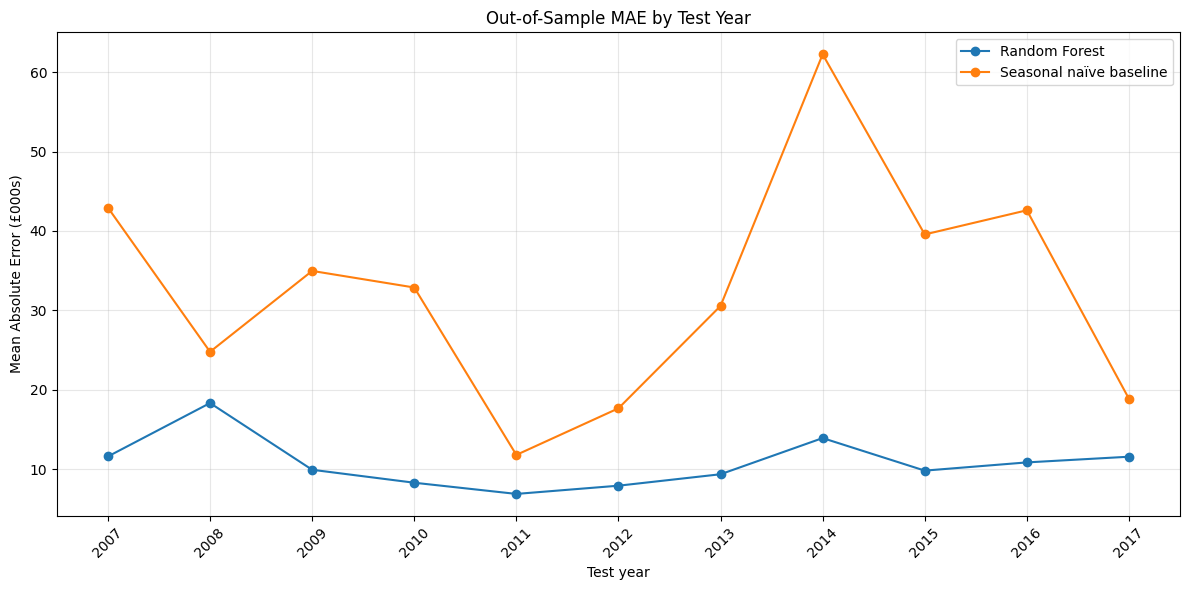

In [42]:
plt.figure(figsize=(12, 6))

for model_name, model_results in yearly_results.groupby("model"):
    plt.plot(
        model_results["test_year"],
        model_results["MAE"] / 1_000,
        marker="o",
        label=model_name
    )

plt.title("Out-of-Sample MAE by Test Year")
plt.xlabel("Test year")
plt.ylabel("Mean Absolute Error (£000s)")
plt.xticks(
    sorted(yearly_results["test_year"].unique()),
    rotation=45
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_mae_by_test_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

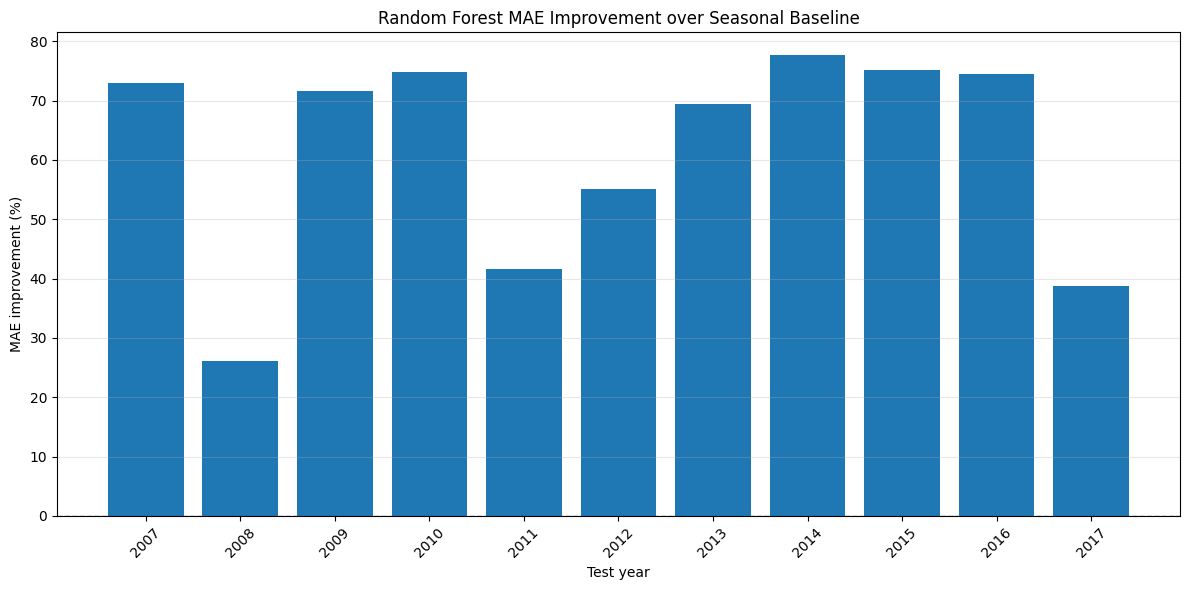

In [43]:
plt.figure(figsize=(12, 6))

plt.bar(
    mae_by_year["test_year"],
    mae_by_year["RF_improvement_over_baseline_pct"]
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Random Forest MAE Improvement over Seasonal Baseline"
)
plt.xlabel("Test year")
plt.ylabel("MAE improvement (%)")
plt.xticks(
    mae_by_year["test_year"],
    rotation=45
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_rf_improvement_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
rf_yearly = (
    yearly_results[
        yearly_results["model"] == "Random Forest"
    ]
    .sort_values("test_year")
    .copy()
)

rf_yearly["training_years"] = (
    rf_yearly["test_year"]
    - first_available_year
)

In [45]:
training_error_correlation = (
    rf_yearly["training_rows"]
    .corr(rf_yearly["MAE"])
)

print(
    "Correlation between training rows and Random Forest MAE:",
    f"{training_error_correlation:.3f}"
)


Correlation between training rows and Random Forest MAE: -0.162


indicates a weak negative relationship between training size and Random Forest MAE, so adding more training data produced only a slight improvement in prediction error.

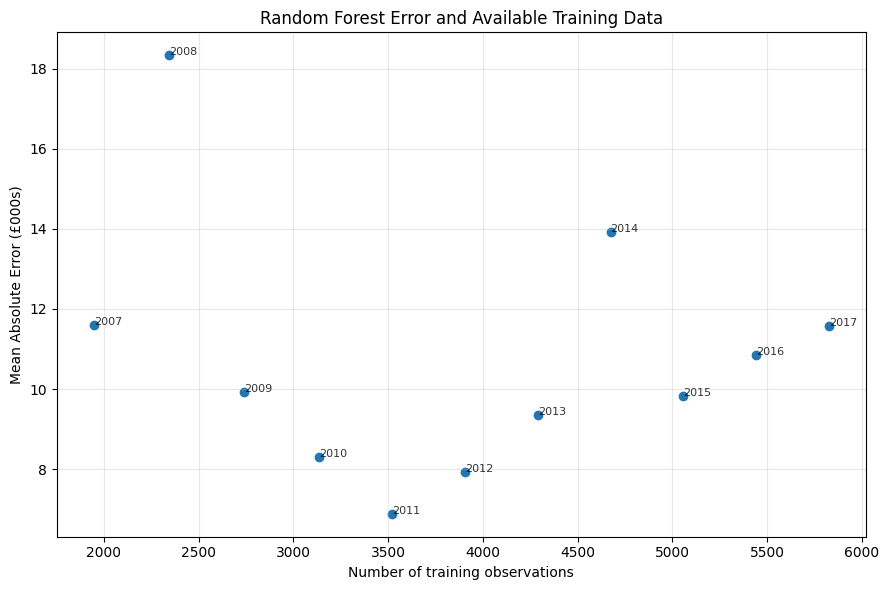

In [46]:
plt.figure(figsize=(9, 6))

plt.scatter(
    rf_yearly["training_rows"],
    rf_yearly["MAE"] / 1_000
)

for _, row in rf_yearly.iterrows():
    plt.annotate(
        int(row["test_year"]),
        (
            row["training_rows"],
            row["MAE"] / 1_000
        ),
        fontsize=8,
        alpha=0.8
    )

plt.title(
    "Random Forest Error and Available Training Data"
)
plt.xlabel("Number of training observations")
plt.ylabel("Mean Absolute Error (£000s)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_training_size_vs_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

a weak negative relationship between training size and Random Forest MAE. More historical data did not consistently reduce error, because some years, such as 2008 and 2014, were more difficult to predict due to changing market conditions

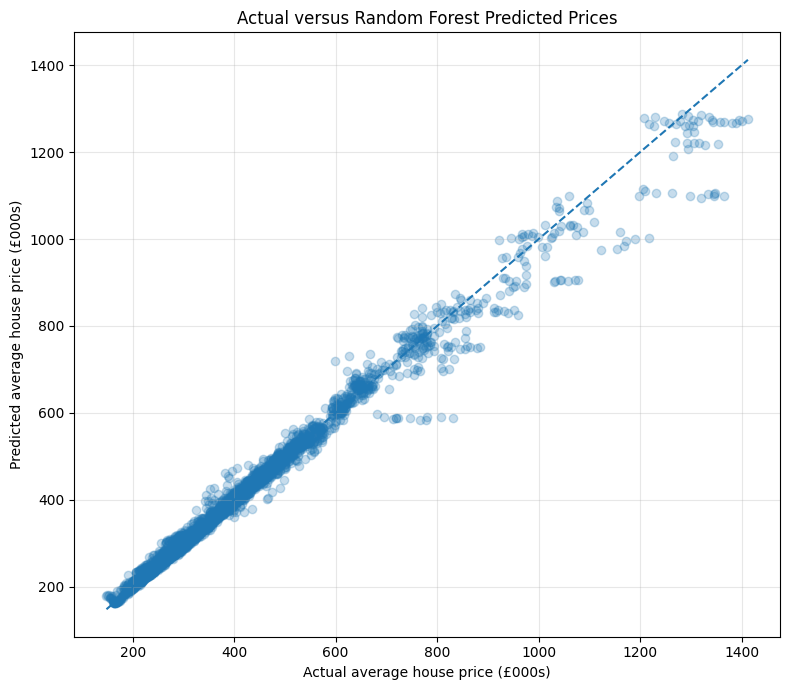

In [47]:
plt.figure(figsize=(8, 7))

plt.scatter(
    all_predictions["actual_price"] / 1_000,
    all_predictions["rf_prediction"] / 1_000,
    alpha=0.25
)

minimum_value = min(
    all_predictions["actual_price"].min(),
    all_predictions["rf_prediction"].min()
) / 1_000

maximum_value = max(
    all_predictions["actual_price"].max(),
    all_predictions["rf_prediction"].max()
) / 1_000

plt.plot(
    [minimum_value, maximum_value],
    [minimum_value, maximum_value],
    linestyle="--"
)

plt.title("Actual versus Random Forest Predicted Prices")
plt.xlabel("Actual average house price (£000s)")
plt.ylabel("Predicted average house price (£000s)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_actual_vs_rf_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Random Forest performs well for most observations, especially in the lower and middle price ranges, but prediction accuracy weakens for the highest-priced observations, where the model tends to underpredict

In [48]:
london_monthly_predictions = (
    all_predictions.groupby("date")
    .agg(
        actual_price=("actual_price", "mean"),
        baseline_prediction=("baseline_prediction", "mean"),
        rf_prediction=("rf_prediction", "mean")
    )
    .reset_index()
)

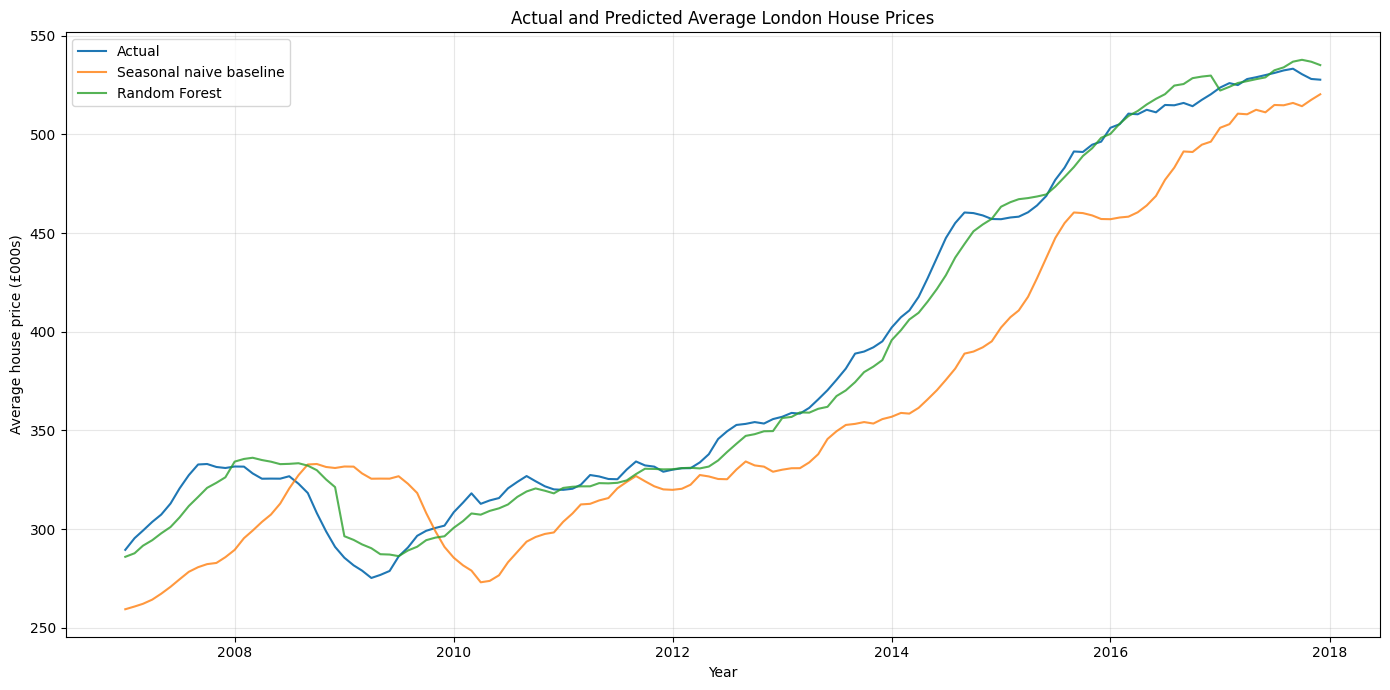

In [49]:
plt.figure(figsize=(14, 7))

plt.plot(
    london_monthly_predictions["date"],
    london_monthly_predictions["actual_price"] / 1_000,
    label="Actual"
)

plt.plot(
    london_monthly_predictions["date"],
    london_monthly_predictions["baseline_prediction"] / 1_000,
    label="Seasonal naive baseline",
    alpha=0.8
)

plt.plot(
    london_monthly_predictions["date"],
    london_monthly_predictions["rf_prediction"] / 1_000,
    label="Random Forest",
    alpha=0.8
)

plt.title(
    "Actual and Predicted Average London House Prices"
)
plt.xlabel("Year")
plt.ylabel("Average house price (£000s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_london_actual_predicted_time_series.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
hardest_years = (
    yearly_results[
        yearly_results["model"] == "Random Forest"
    ]
    .sort_values("MAE", ascending=False)
    [
        [
            "test_year",
            "MAE",
            "RMSE",
            "R_squared",
            "training_rows"
        ]
    ]
)

display(hardest_years)

,test_year,MAE,RMSE,R_squared,training_rows
3,2008,"18,331.212","25,180.457",0.955,2343
15,2014,"13,919.329","36,761.021",0.972,4674
1,2007,"11,605.025","30,869.620",0.924,1947
21,2017,"11,572.460","20,436.813",0.991,5826
19,2016,"10,855.789","17,186.774",0.993,5442
5,2009,"9,928.838","15,442.765",0.981,2739
17,2015,"9,820.362","18,371.699",0.993,5058
13,2013,"9,364.383","26,707.656",0.981,4290
7,2010,"8,296.141","18,849.494",0.980,3135
11,2012,"7,922.915","22,235.655",0.982,3906


In [51]:
display(hardest_years.head(5))

,test_year,MAE,RMSE,R_squared,training_rows
3,2008,"18,331.212","25,180.457",0.955,2343
15,2014,"13,919.329","36,761.021",0.972,4674
1,2007,"11,605.025","30,869.620",0.924,1947
21,2017,"11,572.460","20,436.813",0.991,5826
19,2016,"10,855.789","17,186.774",0.993,5442


In [52]:
borough_error_summary = (
    all_predictions.groupby("area")
    .agg(
        observations=("actual_price", "size"),
        mean_actual_price=("actual_price", "mean"),
        baseline_MAE=(
            "baseline_absolute_error",
            "mean"
        ),
        rf_MAE=(
            "rf_absolute_error",
            "mean"
        ),
        rf_median_absolute_error=(
            "rf_absolute_error",
            "median"
        ),
        mean_rf_error=(
            "rf_error",
            "mean"
        )
    )
    .reset_index()
)

borough_error_summary["RF_improvement_pct"] = (
    (
        borough_error_summary["baseline_MAE"]
        - borough_error_summary["rf_MAE"]
    )
    / borough_error_summary["baseline_MAE"]
) * 100

borough_error_summary = borough_error_summary.sort_values(
    "rf_MAE",
    ascending=False
)

display(borough_error_summary)

,area,observations,mean_actual_price,baseline_MAE,rf_MAE,rf_median_absolute_error,mean_rf_error,RF_improvement_pct
19,kensington and chelsea,132,"1,029,952.939","95,462.311","95,326.020","85,354.283","85,560.061",0.143
6,city of london,39,"420,201.000","61,569.000","32,109.040","28,391.073",321.550,47.849
32,westminster,132,"750,953.697","61,681.326","26,083.634","22,891.957","8,245.276",57.712
5,camden,132,"630,359.841","53,334.970","17,374.313","12,482.500","-1,750.988",67.424
12,hammersmith and fulham,132,"599,810.750","49,638.636","14,315.854","11,608.488","-1,901.785",71.160
18,islington,132,"490,757.129","43,791.348","13,802.233","11,089.080","-3,395.392",68.482
26,richmond upon thames,132,"500,519.909","41,345.083","12,544.262","9,369.593","-3,138.164",69.660
31,wandsworth,132,"458,874.614","36,878.576","9,839.533","7,254.676",-896.950,73.319
11,hackney,132,"385,608.955","34,383.758","9,447.490","6,453.266","-1,409.541",72.523
13,haringey,132,"385,401.348","34,763.386","9,073.851","8,515.920",-578.036,73.898


In [53]:
hardest_boroughs = borough_error_summary.head(10)

display(hardest_boroughs)

,area,observations,mean_actual_price,baseline_MAE,rf_MAE,rf_median_absolute_error,mean_rf_error,RF_improvement_pct
19,kensington and chelsea,132,"1,029,952.939","95,462.311","95,326.020","85,354.283","85,560.061",0.143
6,city of london,39,"420,201.000","61,569.000","32,109.040","28,391.073",321.550,47.849
32,westminster,132,"750,953.697","61,681.326","26,083.634","22,891.957","8,245.276",57.712
5,camden,132,"630,359.841","53,334.970","17,374.313","12,482.500","-1,750.988",67.424
12,hammersmith and fulham,132,"599,810.750","49,638.636","14,315.854","11,608.488","-1,901.785",71.160
18,islington,132,"490,757.129","43,791.348","13,802.233","11,089.080","-3,395.392",68.482
26,richmond upon thames,132,"500,519.909","41,345.083","12,544.262","9,369.593","-3,138.164",69.660
31,wandsworth,132,"458,874.614","36,878.576","9,839.533","7,254.676",-896.950,73.319
11,hackney,132,"385,608.955","34,383.758","9,447.490","6,453.266","-1,409.541",72.523
13,haringey,132,"385,401.348","34,763.386","9,073.851","8,515.920",-578.036,73.898


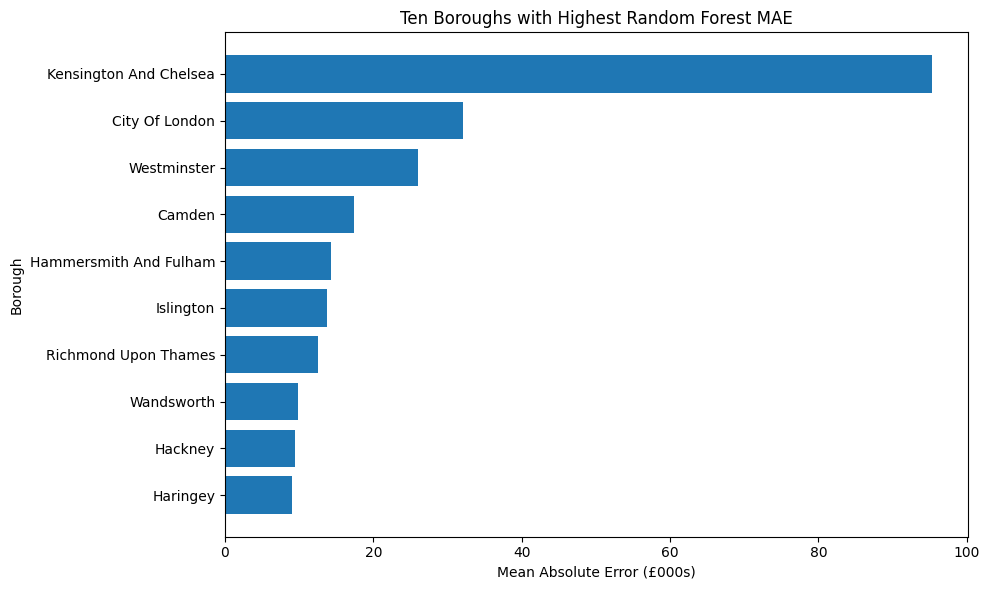

In [54]:
plot_data = (
    hardest_boroughs
    .sort_values("rf_MAE")
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["area"].str.title(),
    plot_data["rf_MAE"] / 1_000
)

plt.title("Ten Boroughs with Highest Random Forest MAE")
plt.xlabel("Mean Absolute Error (£000s)")
plt.ylabel("Borough")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_highest_error_boroughs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [55]:
easiest_boroughs = (
    borough_error_summary
    .sort_values("rf_MAE")
    .head(10)
)

display(easiest_boroughs)

,area,observations,mean_actual_price,baseline_MAE,rf_MAE,rf_median_absolute_error,mean_rf_error,RF_improvement_pct
15,havering,132,"255,669.894","20,343.879","3,903.250","2,554.047","-1,990.439",80.814
7,croydon,132,"261,271.606","22,424.061","4,225.309","3,042.797","-2,141.690",81.157
2,bexley,132,"236,438.689","18,134.333","4,232.919","2,823.409","-1,436.134",76.658
9,enfield,132,"283,324.803","22,523.182","4,409.526","3,418.285","-1,555.613",80.422
16,hillingdon,132,"294,677.053","22,814.985","4,487.734","2,770.151","-2,101.743",80.330
28,sutton,132,"273,628.250","22,162.015","4,537.766","2,861.544","-1,517.144",79.525
22,lewisham,132,"282,890.303","24,284.932","4,598.829","3,471.622","-1,492.134",81.063
10,greenwich,132,"273,977.606","22,539.545","4,656.271","3,369.628","-1,358.793",79.342
4,bromley,132,"321,113.667","24,199.932","5,041.562","3,351.925","-1,964.464",79.167
14,harrow,132,"341,650.068","26,471.311","5,059.112","3,715.590","-1,560.175",80.888


In [56]:
price_error_correlation = (
    borough_error_summary["mean_actual_price"]
    .corr(borough_error_summary["rf_MAE"])
)

print(
    "Correlation between borough price level and RF MAE:",
    f"{price_error_correlation:.3f}"
)

Correlation between borough price level and RF MAE: 0.851


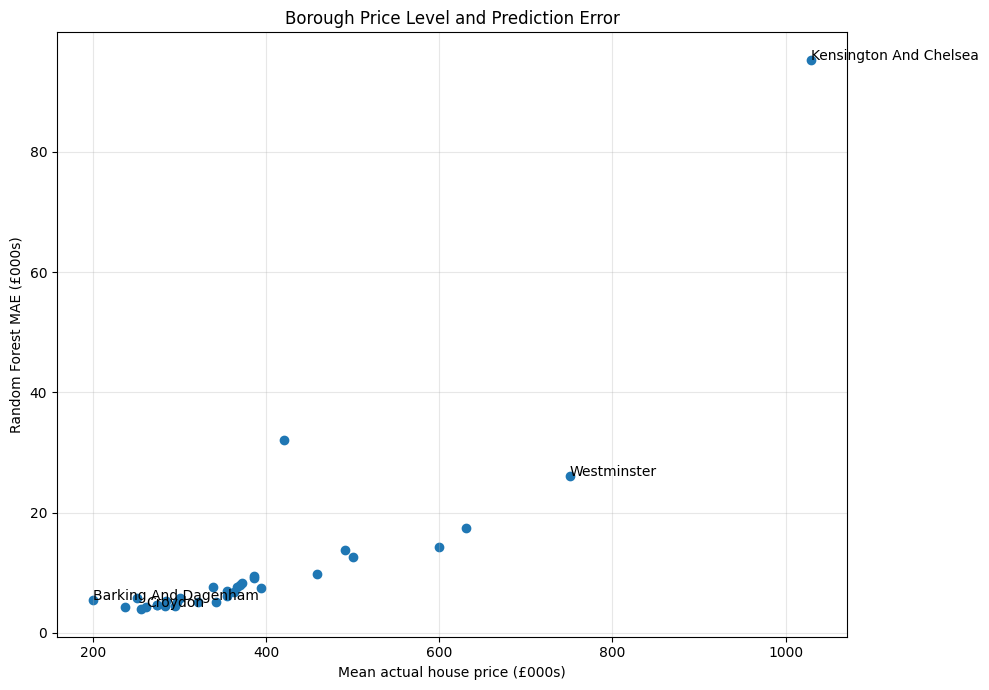

In [57]:
plt.figure(figsize=(10, 7))

plt.scatter(
    borough_error_summary["mean_actual_price"] / 1_000,
    borough_error_summary["rf_MAE"] / 1_000
)

important_areas = [
    "westminster",
    "kensington and chelsea",
    "croydon",
    "barking and dagenham"
]

for _, row in borough_error_summary.iterrows():
    if row["area"].lower() in important_areas:
        plt.annotate(
            row["area"].title(),
            (
                row["mean_actual_price"] / 1_000,
                row["rf_MAE"] / 1_000
            )
        )

plt.title("Borough Price Level and Prediction Error")
plt.xlabel("Mean actual house price (£000s)")
plt.ylabel("Random Forest MAE (£000s)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_borough_price_vs_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [58]:
borough_bias = (
    all_predictions.groupby("area")
    .agg(
        mean_error=("rf_error", "mean"),
        median_error=("rf_error", "median")
    )
    .sort_values("mean_error")
)

display(borough_bias)

,mean_error,median_error
area,,
islington,"-3,395.392","1,196.923"
richmond upon thames,"-3,138.164",-994.278
tower hamlets,"-2,598.611",-948.609
hounslow,"-2,402.824",-757.332
croydon,"-2,141.690",-992.941
hillingdon,"-2,101.743",-851.303
redbridge,"-1,991.987",-332.604
havering,"-1,990.439",-697.897
bromley,"-1,964.464",-691.967


positive error = model underpredicted

negative error = model overpredicted

In [59]:
most_underpredicted = borough_bias.tail(10)
most_overpredicted = borough_bias.head(10)

print("Most underpredicted boroughs:")
display(most_underpredicted)

print("Most overpredicted boroughs:")
display(most_overpredicted)

Most underpredicted boroughs:


,mean_error,median_error
area,,
southwark,"-1,317.917",-355.837
kingston upon thames,"-1,137.250",220.900
brent,"-1,036.424",15.154
merton,"-1,025.192",825.464
wandsworth,-896.950,"2,036.414"
barking and dagenham,-633.377,"1,453.327"
haringey,-578.036,927.675
city of london,321.550,302.098
westminster,"8,245.276","7,281.199"


Most overpredicted boroughs:


,mean_error,median_error
area,,
islington,"-3,395.392","1,196.923"
richmond upon thames,"-3,138.164",-994.278
tower hamlets,"-2,598.611",-948.609
hounslow,"-2,402.824",-757.332
croydon,"-2,141.690",-992.941
hillingdon,"-2,101.743",-851.303
redbridge,"-1,991.987",-332.604
havering,"-1,990.439",-697.897
bromley,"-1,964.464",-691.967


In [60]:
all_predictions["month"] = (
    all_predictions["date"].dt.month
)

all_predictions["month_name"] = (
    all_predictions["date"].dt.month_name().str[:3]
)

monthly_error_summary = (
    all_predictions.groupby(
        ["month", "month_name"]
    )
    .agg(
        baseline_MAE=(
            "baseline_absolute_error",
            "mean"
        ),
        rf_MAE=(
            "rf_absolute_error",
            "mean"
        ),
        mean_rf_error=(
            "rf_error",
            "mean"
        )
    )
    .reset_index()
    .sort_values("month")
)

display(monthly_error_summary)

,month,month_name,baseline_MAE,rf_MAE,mean_rf_error
0,1,Jan,"33,154.803","7,687.850",185.838
1,2,Feb,"34,179.798","8,594.558",145.852
2,3,Mar,"34,433.295","9,480.057",-681.108
3,4,Apr,"34,254.527","9,787.956",110.131
4,5,May,"33,685.885","9,753.924","1,391.406"
5,6,Jun,"33,245.701","10,468.192","2,898.147"
6,7,Jul,"32,702.811","11,033.365","4,748.545"
7,8,Aug,"32,217.459","12,020.704","4,630.413"
8,9,Sep,"31,719.163","12,119.671","4,854.191"
9,10,Oct,"30,867.603","11,492.343",599.164


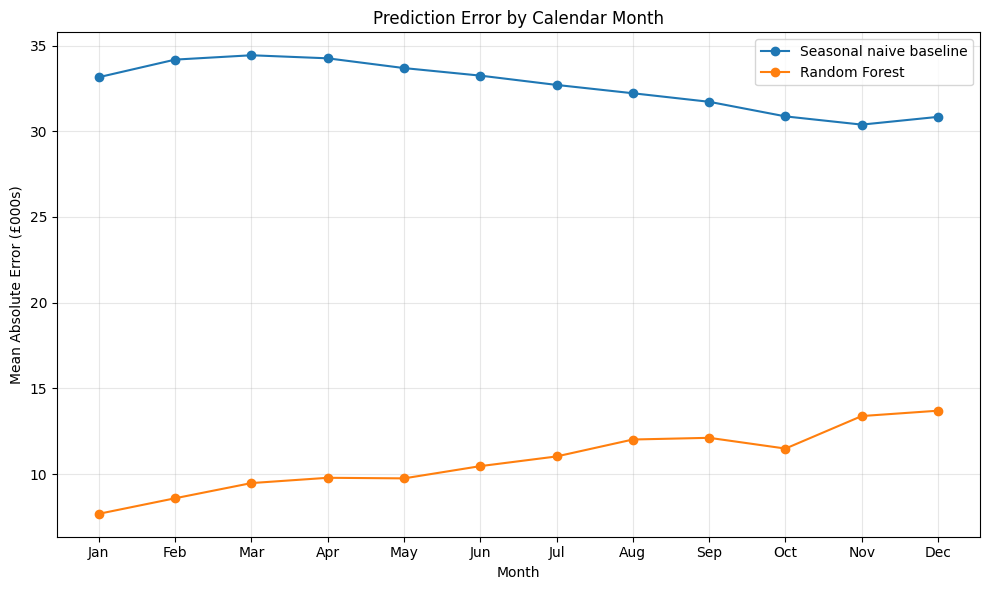

In [61]:
plt.figure(figsize=(10, 6))

plt.plot(
    monthly_error_summary["month_name"],
    monthly_error_summary["baseline_MAE"] / 1_000,
    marker="o",
    label="Seasonal naive baseline"
)

plt.plot(
    monthly_error_summary["month_name"],
    monthly_error_summary["rf_MAE"] / 1_000,
    marker="o",
    label="Random Forest"
)

plt.title("Prediction Error by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Mean Absolute Error (£000s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_mae_by_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Random Forest clearly outperforms the seasonal naive baseline in every month with much lower MAE throughout the year.

In [62]:
largest_errors = (
    all_predictions.sort_values(
        "rf_absolute_error",
        ascending=False
    )
    [
        [
            "date",
            "area",
            "actual_price",
            "rf_prediction",
            "rf_error",
            "rf_absolute_error"
        ]
    ]
    .head(20)
)

display(largest_errors)

,date,area,actual_price,rf_prediction,rf_error,rf_absolute_error
3065,2014-11-01,kensington and chelsea,1365050,"1,099,152.173","265,897.827","265,897.827"
2937,2014-07-01,kensington and chelsea,1345616,"1,098,692.293","246,923.707","246,923.707"
283,2007-09-01,kensington and chelsea,830950,"588,751.255","242,198.745","242,198.745"
2969,2014-08-01,kensington and chelsea,1347030,"1,105,738.401","241,291.599","241,291.599"
3001,2014-09-01,kensington and chelsea,1344464,"1,103,888.228","240,575.772","240,575.772"
3033,2014-10-01,kensington and chelsea,1334423,"1,103,307.664","231,115.336","231,115.336"
3097,2014-12-01,kensington and chelsea,1319380,"1,095,069.195","224,310.805","224,310.805"
316,2007-10-01,kensington and chelsea,808270,"589,861.688","218,408.312","218,408.312"
2617,2013-09-01,kensington and chelsea,1217729,"1,002,791.108","214,937.892","214,937.892"
2905,2014-06-01,kensington and chelsea,1297755,"1,099,947.793","197,807.207","197,807.207"


In [63]:
importance_year = max(backtest_years)

importance_model = fitted_models[importance_year]

importance_test_df = model_df[
    model_df["year"] == importance_year
].copy()

X_importance = importance_test_df[all_features]
y_importance = importance_test_df[target]

print("Importance evaluation year:", importance_year)
print("Importance observations:", len(importance_test_df))

Importance evaluation year: 2017
Importance observations: 384


In [64]:
permutation_results = permutation_importance(
    importance_model,
    X_importance,
    y_importance,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

In [65]:
permutation_importance_df = pd.DataFrame({
    "feature": all_features,
    "importance_mean": permutation_results.importances_mean,
    "importance_std": permutation_results.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(permutation_importance_df)

,feature,importance_mean,importance_std
3,price_lag_1,"31,090.999",760.837
8,price_rolling_mean_6,"20,593.269",645.138
7,price_rolling_mean_3,"19,680.790",565.365
9,price_rolling_mean_12,"18,229.536",546.716
4,price_lag_3,"14,750.904",485.419
5,price_lag_6,"11,462.131",432.003
6,price_lag_12,"10,763.057",409.376
26,area,"3,874.045",160.851
10,price_rolling_std_12,"1,727.544",235.736
11,price_mom_growth_lag_1,285.931,47.019




Larger positive values indicate greater deterioration in performance when the feature is shuffled.

Near-zero importance suggests limited additional predictive information.

Negative values may arise because of sampling variation or correlated predictors.

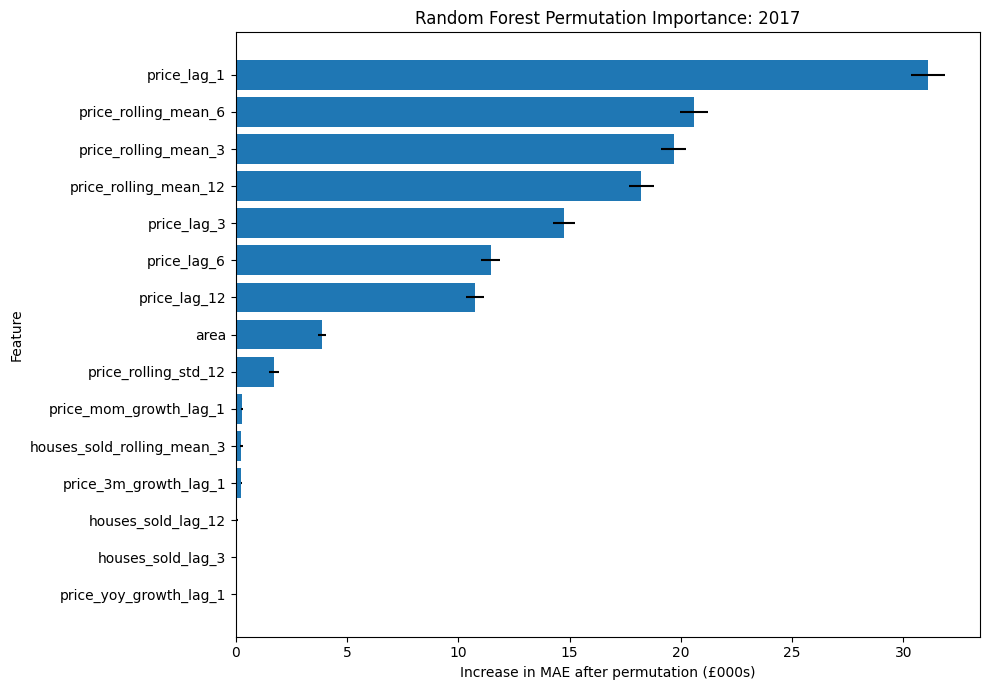

In [66]:
top_n = 15

importance_plot_data = (
    permutation_importance_df
    .head(top_n)
    .sort_values("importance_mean")
)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_plot_data["feature"],
    importance_plot_data["importance_mean"] / 1_000,
    xerr=importance_plot_data["importance_std"] / 1_000
)

plt.title(
    f"Random Forest Permutation Importance: {importance_year}"
)
plt.xlabel("Increase in MAE after permutation (£000s)")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [67]:
def assign_feature_group(feature_name):
    if feature_name.startswith("price_lag"):
        return "Price lags"

    if feature_name.startswith("price_rolling"):
        return "Price rolling features"

    if "price_" in feature_name and "growth" in feature_name:
        return "Price growth"

    if feature_name.startswith("houses_sold"):
        return "Transaction activity"

    if feature_name.startswith("cpi"):
        return "Inflation"

    if feature_name.startswith("bank_rate"):
        return "Bank Rate"

    if feature_name in ["month_sin", "month_cos"]:
        return "Seasonality"

    if feature_name == "time_index":
        return "Time trend"

    if feature_name == "area":
        return "Borough"

    return "Other"

In [68]:
simple_numeric_features = [
    "time_index",
    "month_sin",
    "month_cos",
    "price_lag_1",
    "price_lag_12",
    "houses_sold_lag_1",
    "cpi_lag_1",
    "bank_rate_lag_1"
]

simple_categorical_features = ["area"]

simple_features = (
    simple_numeric_features
    + simple_categorical_features
)

In [69]:
#Simple Pipeline
simple_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            "passthrough",
            simple_numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            simple_categorical_features
        )
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

simple_rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", simple_preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=15,
                min_samples_split=5,
                min_samples_leaf=3,
                max_features="sqrt",
                bootstrap=True,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

In [70]:
simple_yearly_results, simple_predictions, _ = (
    run_yearly_backtest(
        data=model_df,
        test_years=backtest_years,
        feature_columns=simple_features,
        target_column=target,
        model_pipeline=simple_rf_pipeline
    )
)


Processing test year: 2007
Training period: 2002-02-01 to 2006-12-01
Testing period: 2007-01-01 to 2007-12-01
Baseline MAE: £42,937
Random Forest MAE: £19,351
Random Forest improvement: 54.93%

Processing test year: 2008
Training period: 2002-02-01 to 2007-12-01
Testing period: 2008-01-01 to 2008-12-01
Baseline MAE: £24,785
Random Forest MAE: £25,652
Random Forest improvement: -3.50%

Processing test year: 2009
Training period: 2002-02-01 to 2008-12-01
Testing period: 2009-01-01 to 2009-12-01
Baseline MAE: £34,972
Random Forest MAE: £14,004
Random Forest improvement: 59.96%

Processing test year: 2010
Training period: 2002-02-01 to 2009-12-01
Testing period: 2010-01-01 to 2010-12-01
Baseline MAE: £32,882
Random Forest MAE: £18,716
Random Forest improvement: 43.08%

Processing test year: 2011
Training period: 2002-02-01 to 2010-12-01
Testing period: 2011-01-01 to 2011-12-01
Baseline MAE: £11,800
Random Forest MAE: £8,737
Random Forest improvement: 25.96%

Processing test year: 2012
Tra

In [71]:
simple_yearly_results["model"] = (
    "Random Forest — simple features"
)

yearly_results["model"] = yearly_results["model"].replace({
    "Random Forest": "Random Forest — extended features"
})

In [72]:
sensitivity_results = pd.concat(
    [
        yearly_results,
        simple_yearly_results
    ],
    ignore_index=True
)

display(
    sensitivity_results.groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        median_MAE=("MAE", "median"),
        mean_RMSE=("RMSE", "mean"),
        mean_R_squared=("R_squared", "mean")
    )
    .sort_values("mean_MAE")
)

,mean_MAE,median_MAE,mean_RMSE,mean_R_squared
model,,,,
Random Forest — extended features,"10,773.039","9,928.838","22,580.927",0.976
Random Forest — simple features,"24,693.614","19,111.590","34,708.911",0.942
Seasonal naïve baseline,"32,627.941","32,882.473","40,618.412",0.923


In [73]:
rf_configurations = {
    "RF shallow": {
        "n_estimators": 300,
        "max_depth": 10,
        "min_samples_leaf": 5,
        "max_features": "sqrt"
    },
    "RF primary": {
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_leaf": 3,
        "max_features": "sqrt"
    },
    "RF unrestricted depth": {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 3,
        "max_features": "sqrt"
    }
}

In [74]:
development_years = backtest_years[-5:]

print("Development years used for configuration comparison:")
print(development_years)

Development years used for configuration comparison:
[2013, 2014, 2015, 2016, 2017]


In [75]:
configuration_records = []

for configuration_name, parameters in rf_configurations.items():

    configuration_model = RandomForestRegressor(
        n_estimators=parameters["n_estimators"],
        max_depth=parameters["max_depth"],
        min_samples_leaf=parameters["min_samples_leaf"],
        max_features=parameters["max_features"],
        min_samples_split=5,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    configuration_pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", configuration_model)
        ]
    )

    configuration_results, _, _ = run_yearly_backtest(
        data=model_df,
        test_years=development_years,
        feature_columns=all_features,
        target_column=target,
        model_pipeline=configuration_pipeline
    )

    rf_configuration_results = configuration_results[
        configuration_results["model"] == "Random Forest"
    ].copy()

    configuration_records.append({
        "configuration": configuration_name,
        "mean_MAE": rf_configuration_results["MAE"].mean(),
        "median_MAE": rf_configuration_results["MAE"].median(),
        "mean_RMSE": rf_configuration_results["RMSE"].mean()
    })

configuration_comparison = pd.DataFrame(
    configuration_records
).sort_values("mean_MAE")

display(configuration_comparison)


Processing test year: 2013
Training period: 2002-02-01 to 2012-12-01
Testing period: 2013-01-01 to 2013-12-01
Baseline MAE: £30,564
Random Forest MAE: £10,542
Random Forest improvement: 65.51%

Processing test year: 2014
Training period: 2002-02-01 to 2013-12-01
Testing period: 2014-01-01 to 2014-12-01
Baseline MAE: £62,252
Random Forest MAE: £14,817
Random Forest improvement: 76.20%

Processing test year: 2015
Training period: 2002-02-01 to 2014-12-01
Testing period: 2015-01-01 to 2015-12-01
Baseline MAE: £39,566
Random Forest MAE: £10,151
Random Forest improvement: 74.34%

Processing test year: 2016
Training period: 2002-02-01 to 2015-12-01
Testing period: 2016-01-01 to 2016-12-01
Baseline MAE: £42,609
Random Forest MAE: £10,656
Random Forest improvement: 74.99%

Processing test year: 2017
Training period: 2002-02-01 to 2016-12-01
Testing period: 2017-01-01 to 2017-12-01
Baseline MAE: £18,872
Random Forest MAE: £13,397
Random Forest improvement: 29.01%

Processing test year: 2013
Tr

,configuration,mean_MAE,median_MAE,mean_RMSE
2,RF unrestricted depth,"10,954.292","11,051.608","22,845.753"
1,RF primary,"11,106.465","10,855.789","23,892.793"
0,RF shallow,"11,912.677","10,656.047","25,503.140"


## Final hold-out evaluation

The final complete year was excluded from model selection and sensitivity analysis.

After selecting the final Random Forest configuration, the model was trained using all observations preceding the final year and evaluated once on the untouched final hold-out period.

In [76]:
final_train_df = model_df[
    model_df["year"] < final_holdout_year
].copy()

final_test_df = model_df[
    model_df["year"] == final_holdout_year
].copy()

print("Final training period:")
print(
    final_train_df["date"].min(),
    "to",
    final_train_df["date"].max()
)

print("Final test period:")
print(
    final_test_df["date"].min(),
    "to",
    final_test_df["date"].max()
)

print("Training rows:", len(final_train_df))
print("Testing rows:", len(final_test_df))

Final training period:
2002-02-01 00:00:00 to 2017-12-01 00:00:00
Final test period:
2018-01-01 00:00:00 to 2018-12-01 00:00:00
Training rows: 6210
Testing rows: 384


In [77]:
final_rf_pipeline = clone(rf_pipeline)

X_final_train = final_train_df[all_features]
y_final_train = final_train_df[target]

X_final_test = final_test_df[all_features]
y_final_test = final_test_df[target]

final_rf_pipeline.fit(
    X_final_train,
    y_final_train
)

final_rf_predictions = final_rf_pipeline.predict(
    X_final_test
)

In [78]:
final_baseline_predictions = (
    final_test_df["price_lag_12"]
)

In [79]:
final_baseline_metrics = calculate_regression_metrics(
    y_final_test,
    final_baseline_predictions
)

final_rf_metrics = calculate_regression_metrics(
    y_final_test,
    final_rf_predictions
)

final_holdout_results = pd.DataFrame([
    {
        "model": "Seasonal naive baseline",
        **final_baseline_metrics
    },
    {
        "model": "Random Forest",
        **final_rf_metrics
    }
])

display(final_holdout_results)

,model,MAE,RMSE,R_squared
0,Seasonal naive baseline,"14,130.609","24,188.542",0.987
1,Random Forest,"10,889.785","20,013.089",0.991


In [80]:
final_improvement_pct = (
    (
        final_baseline_metrics["MAE"]
        - final_rf_metrics["MAE"]
    )
    / final_baseline_metrics["MAE"]
) * 100

print(
    "Final hold-out MAE improvement:",
    f"{final_improvement_pct:.2f}%"
)

Final hold-out MAE improvement: 22.93%


In [81]:
final_predictions = final_test_df[
    [
        "date",
        "year",
        "area",
        "average_price",
        "price_lag_12"
    ]
].copy()

final_predictions = final_predictions.rename(
    columns={
        "average_price": "actual_price",
        "price_lag_12": "baseline_prediction"
    }
)

final_predictions["rf_prediction"] = (
    final_rf_predictions
)

final_predictions["baseline_absolute_error"] = (
    final_predictions["actual_price"]
    - final_predictions["baseline_prediction"]
).abs()

final_predictions["rf_absolute_error"] = (
    final_predictions["actual_price"]
    - final_predictions["rf_prediction"]
).abs()

display(final_predictions.head())

,date,year,area,actual_price,baseline_prediction,rf_prediction,baseline_absolute_error,rf_absolute_error
6210,2018-01-01,2018,barking and dagenham,291548,"282,441.000","294,625.657","9,107.000","3,077.657"
6211,2018-01-01,2018,barnet,531832,"532,924.000","537,211.768","1,092.000","5,379.768"
6212,2018-01-01,2018,bexley,342096,"330,066.000","344,093.611","12,030.000","1,997.611"
6213,2018-01-01,2018,brent,493882,"472,373.000","492,371.806","21,509.000","1,510.194"
6214,2018-01-01,2018,bromley,446737,"436,538.000","449,314.852","10,199.000","2,577.852"


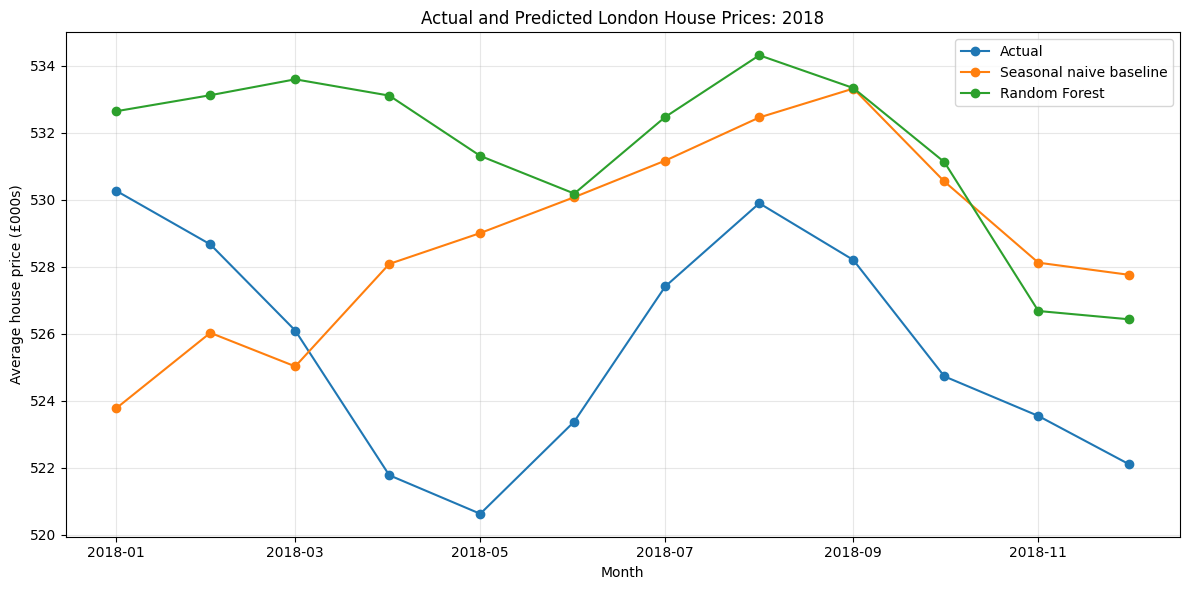

In [82]:
final_monthly = (
    final_predictions.groupby("date")
    .agg(
        actual_price=("actual_price", "mean"),
        baseline_prediction=(
            "baseline_prediction",
            "mean"
        ),
        rf_prediction=("rf_prediction", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    final_monthly["date"],
    final_monthly["actual_price"] / 1_000,
    marker="o",
    label="Actual"
)

plt.plot(
    final_monthly["date"],
    final_monthly["baseline_prediction"] / 1_000,
    marker="o",
    label="Seasonal naive baseline"
)

plt.plot(
    final_monthly["date"],
    final_monthly["rf_prediction"] / 1_000,
    marker="o",
    label="Random Forest"
)

plt.title(
    f"Actual and Predicted London House Prices: "
    f"{final_holdout_year}"
)
plt.xlabel("Month")
plt.ylabel("Average house price (£000s)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_final_holdout_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [83]:
print(final_test_df.columns.tolist())

['date', 'year', 'average_price', 'price_lag_12', 'time_index', 'month_sin', 'month_cos', 'price_lag_1', 'price_lag_3', 'price_lag_6', 'price_rolling_mean_3', 'price_rolling_mean_6', 'price_rolling_mean_12', 'price_rolling_std_12', 'price_mom_growth_lag_1', 'price_3m_growth_lag_1', 'price_yoy_growth_lag_1', 'houses_sold_lag_1', 'houses_sold_lag_3', 'houses_sold_lag_12', 'houses_sold_rolling_mean_3', 'houses_sold_rolling_mean_12', 'cpi_lag_1', 'cpi_lag_3', 'cpi_lag_12', 'bank_rate_lag_1', 'bank_rate_lag_3', 'bank_rate_lag_12', 'bank_rate_change_1m_lag_1', 'area']
